In [1]:
# Cell 1: Import and load clean data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('../data/processed/merged_clean.csv', index_col=0, parse_dates=True)

print("Data loaded :)")
print(f"Shape: {df.shape}")
print(f"Date range: {df.index[0].date()} to {df.index[-1].date()}")
print(f"\nColumns: {df.columns.tolist()}")

Data loaded :)
Shape: (302, 13)
Date range: 2001-04-01 to 2026-05-01

Columns: ['cpi', 'wages', 'unemployment', 'oil_price', 'gbp_usd', 'us_cpi', 'oil_lag1', 'oil_lag2', 'oil_lag3', 'gbp_lag1', 'gbp_lag2', 'wages_lag1', 'wages_lag3']


In [2]:
# Cell 2: Define features and target variable
# Features (X) = Variables used to predict
# Target (y) = Variable to be predicted (CPI)

features = ['oil_lag1', 'oil_lag2', 'oil_lag3', 
            'gbp_lag1', 'gbp_lag2', 
            'wages_lag1', 'wages_lag3',
            'unemployment']

target = 'cpi'

X = df[features]
y = df[target]

# Train/test split, using first chunk for training and last chunk for testing

split_idx = int(len(X) * 0.8)  # 80% train, 20% test

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Training period: {X_train.index[0].date()} to {X_train.index[-1].date()}")
print(f"Test period:     {X_test.index[0].date()} to {X_test.index[-1].date()}")
print(f"\nTraining observations: {len(X_train)}")
print(f"Test observations:     {len(X_test)}")

Training period: 2001-04-01 to 2021-04-01
Test period:     2021-05-01 to 2026-05-01

Training observations: 241
Test observations:     61


In [3]:
# Cell 3: Fit the linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("=== MODEL PERFORMANCE ===")
print(f"Mean Absolute Error (MAE): {mae:.2f} percentage points")
print(f"R² Score: {r2:.3f}")
print(f"\nWhat this means:")
print(f"On average our model's CPI forecast is off by {mae:.2f} percentage points")
print(f"The model explains {r2*100:.1f}% of the variation in CPI")

=== MODEL PERFORMANCE ===
Mean Absolute Error (MAE): 2.47 percentage points
R² Score: -0.444

What this means:
On average our model's CPI forecast is off by 2.47 percentage points
The model explains -44.4% of the variation in CPI


In [7]:
# Cell 4: Evaluate performance on pre-2022 data only, to separate "normal" inflation dynamics from the unprecedented 2022 spike

# Find where 2022 starts in our test set
pre_2022_mask = y_test.index < '2022-01-01'

y_test_pre2022 = y_test[pre_2022_mask]
y_pred_pre2022 = y_pred[:sum(pre_2022_mask)]

mae_pre2022 = mean_absolute_error(y_test_pre2022, y_pred_pre2022)
r2_pre2022 = r2_score(y_test_pre2022, y_pred_pre2022)

print("=== PERFORMANCE BEFORE 2022 ENERGY SHOCK ===")
print(f"MAE: {mae_pre2022:.2f} percentage points")
print(f"R²: {r2_pre2022:.3f}")

print("\n=== PERFORMANCE FULL TEST PERIOD (inc. 2022 shock) ===")
print(f"MAE: {mae:.2f} percentage points")
print(f"R²: {r2:.3f}")

print("\nThe difference between these two shows how much")
print("the 2022 energy shock has hurt the model's performance.")

=== PERFORMANCE BEFORE 2022 ENERGY SHOCK ===
MAE: 1.15 percentage points
R²: -0.732

=== PERFORMANCE FULL TEST PERIOD (inc. 2022 shock) ===
MAE: 2.47 percentage points
R²: -0.444

The difference between these two shows how much
the 2022 energy shock has hurt the model's performance.


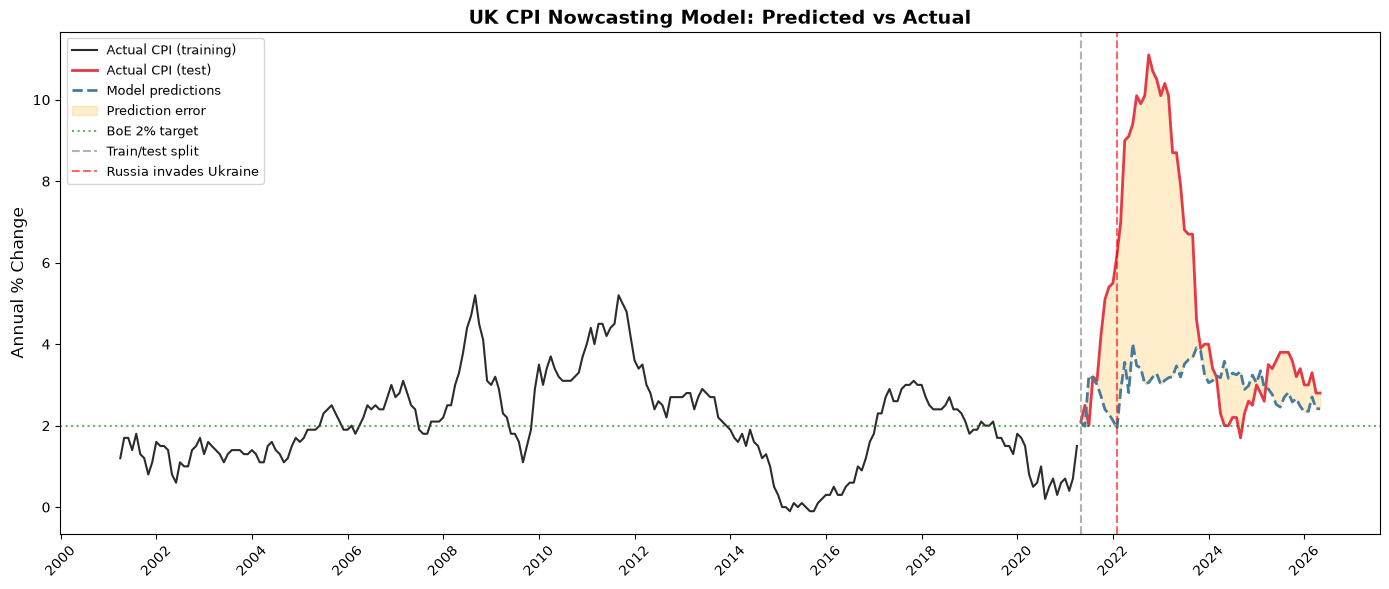

Chart saved :)


In [8]:
# Cell 5: Plot predicted vs actual CPI
fig, ax = plt.subplots(figsize=(14, 6))

# Plot training period actual
ax.plot(y_train.index, y_train, color='#2c2c2c', linewidth=1.5, label='Actual CPI (training)')

# Plot test period actual
ax.plot(y_test.index, y_test, color='#E63946', linewidth=2, label='Actual CPI (test)')

# Plot predictions
ax.plot(y_test.index, y_pred, color='#457B9D', linewidth=2, 
        linestyle='--', label='Model predictions')

# Shade the gap between predicted and actual
ax.fill_between(y_test.index, y_test, y_pred, alpha=0.2, color='orange', label='Prediction error')

# Reference lines
ax.axhline(y=2, color='green', linestyle=':', alpha=0.6, label='BoE 2% target')
ax.axvline(x=pd.Timestamp('2021-05-01'), color='grey', 
           linestyle='--', alpha=0.6, label='Train/test split')
ax.axvline(x=pd.Timestamp('2022-02-01'), color='red',
           linestyle='--', alpha=0.6, label='Russia invades Ukraine')

ax.set_title('UK CPI Nowcasting Model: Predicted vs Actual', 
             fontsize=14, fontweight='bold')
ax.set_ylabel('Annual % Change', fontsize=12)
ax.legend(loc='upper left', fontsize=9)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator(2))
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('../outputs/charts/06_predictions_vs_actual.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved :)")

In [9]:
# Cell 6: Interpret model coefficients
coef_df = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_
}).sort_values('Coefficient', ascending=False)

print("=== MODEL COEFFICIENTS ===")
print(coef_df.to_string(index=False))
print(f"\nIntercept: {model.intercept_:.3f}")

=== MODEL COEFFICIENTS ===
     Feature  Coefficient
    gbp_lag2     2.741271
  wages_lag3     0.204229
unemployment     0.197451
  wages_lag1     0.053671
    oil_lag1     0.022536
    oil_lag2     0.006314
    oil_lag3    -0.006990
    gbp_lag1    -3.384098

Intercept: -0.193


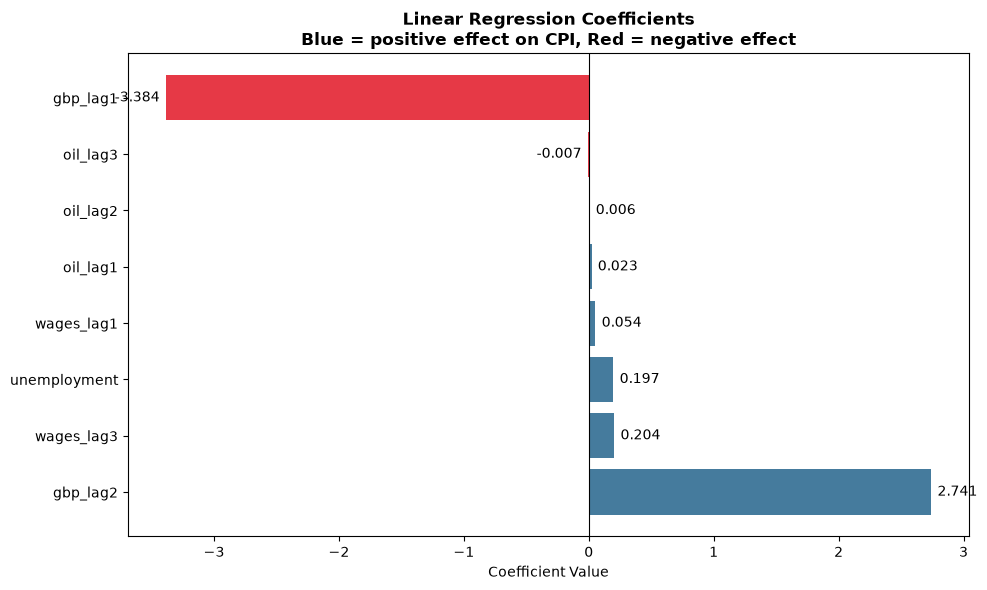

Chart saved:)


In [10]:
# Cell 7: Create coefficient bar chart
fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#E63946' if c < 0 else '#457B9D' for c in coef_df['Coefficient']]

bars = ax.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)

# Add vertical line at zero
ax.axvline(x=0, color='black', linewidth=0.8)

# Add value labels on each bar
for bar, val in zip(bars, coef_df['Coefficient']):
    ax.text(val + (0.05 if val >= 0 else -0.05), 
            bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', 
            ha='left' if val >= 0 else 'right',
            fontsize=10)

ax.set_title('Linear Regression Coefficients\nBlue = positive effect on CPI, Red = negative effect',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Coefficient Value')

plt.tight_layout()
plt.savefig('../outputs/charts/07_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved:)")

In [11]:
# Cell 8: Create rolling window model
# Instead of training once on all data up to 2021, this model is retrained every month using only the most recent 5 years of data
# This allows the model to adapt to changing inflation dynamics over time

window_size = 60  # 60 months = 5 years of training data

rolling_predictions = []
rolling_dates = []

# Loop through the test period month by month
for i in range(len(X_test)):
    # Find where we are in the full dataset
    test_position = split_idx + i
    
    # Use only the most recent 60 months for training
    window_start = test_position - window_size
    window_end = test_position
    
    X_window = X.iloc[window_start:window_end]
    y_window = y.iloc[window_start:window_end]
    
    # Refit model on this window
    rolling_model = LinearRegression()
    rolling_model.fit(X_window, y_window)
    
    # Predict the next month
    prediction = rolling_model.predict(X.iloc[[test_position]])[0]
    rolling_predictions.append(prediction)
    rolling_dates.append(X.index[test_position])

# Convert to series
rolling_pred_series = pd.Series(rolling_predictions, index=rolling_dates)

# Evaluate rolling model
rolling_mae = mean_absolute_error(y_test, rolling_predictions)
rolling_r2 = r2_score(y_test, rolling_predictions)

print("=== ROLLING WINDOW MODEL PERFORMANCE ===")
print(f"MAE: {rolling_mae:.2f} percentage points")
print(f"R²: {rolling_r2:.3f}")
print(f"\n=== STATIC MODEL PERFORMANCE (for comparison) ===")
print(f"MAE: {mae:.2f} percentage points")
print(f"R²: {r2:.3f}")
print(f"\nImprovement in MAE: {mae - rolling_mae:.2f} percentage points")

=== ROLLING WINDOW MODEL PERFORMANCE ===
MAE: 2.20 percentage points
R²: 0.226

=== STATIC MODEL PERFORMANCE (for comparison) ===
MAE: 2.47 percentage points
R²: -0.444

Improvement in MAE: 0.27 percentage points


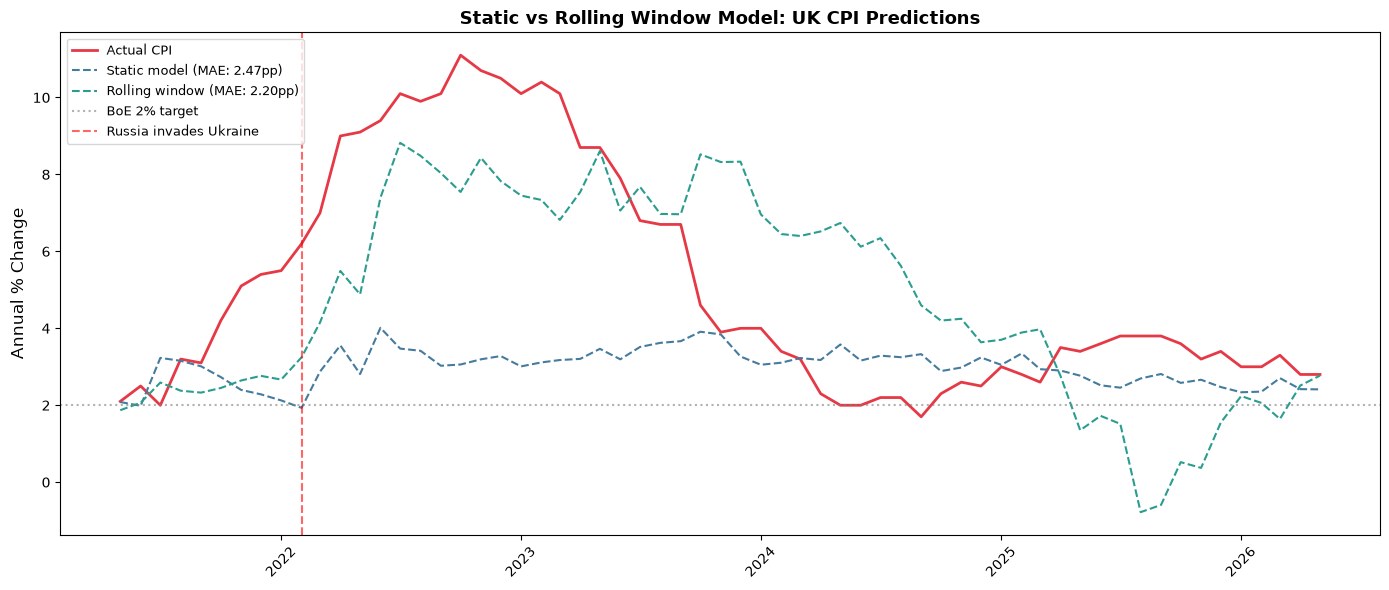

Chart saved :)


In [12]:
# Cell 9: Compare static vs rolling window predictions
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(y_test.index, y_test, color='#E63946', 
        linewidth=2, label='Actual CPI')
ax.plot(y_test.index, y_pred, color='#457B9D', 
        linewidth=1.5, linestyle='--', label=f'Static model (MAE: {mae:.2f}pp)')
ax.plot(rolling_pred_series.index, rolling_pred_series, color='#2A9D8F', 
        linewidth=1.5, linestyle='--', label=f'Rolling window (MAE: {rolling_mae:.2f}pp)')

ax.axhline(y=2, color='grey', linestyle=':', alpha=0.6, label='BoE 2% target')
ax.axvline(x=pd.Timestamp('2022-02-01'), color='red',
           linestyle='--', alpha=0.6, label='Russia invades Ukraine')

ax.set_title('Static vs Rolling Window Model: UK CPI Predictions', 
             fontsize=13, fontweight='bold')
ax.set_ylabel('Annual % Change', fontsize=12)
ax.legend(loc='upper left', fontsize=9)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('../outputs/charts/08_rolling_vs_static.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved :)")